<a href="https://colab.research.google.com/github/zohaibahmedshaikh32-coder/Machine_Learning_labs/blob/main/MlLab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Task 1: Load Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

# Load the Iris dataset from sklearn
iris = load_iris()

# Create a DataFrame for features
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Add target column
df['species'] = iris.target

# Map numerical targets to target species names for display clarity
df['species_name'] = df['species'].map({0: iris.target_names[0],
                                        1: iris.target_names[1],
                                        2: iris.target_names[2]})

print("Dataset loaded successfully!")
print("First 5 rows of the dataset:")
df.head()

Dataset loaded successfully!
First 5 rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
 5   species_name       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

--- Dataset Shape (Rows, Columns) ---
(150, 6)

--- Missing Values Check ---
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

--- Statistical Summary ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


<Figure size 1000x800 with 0 Axes>

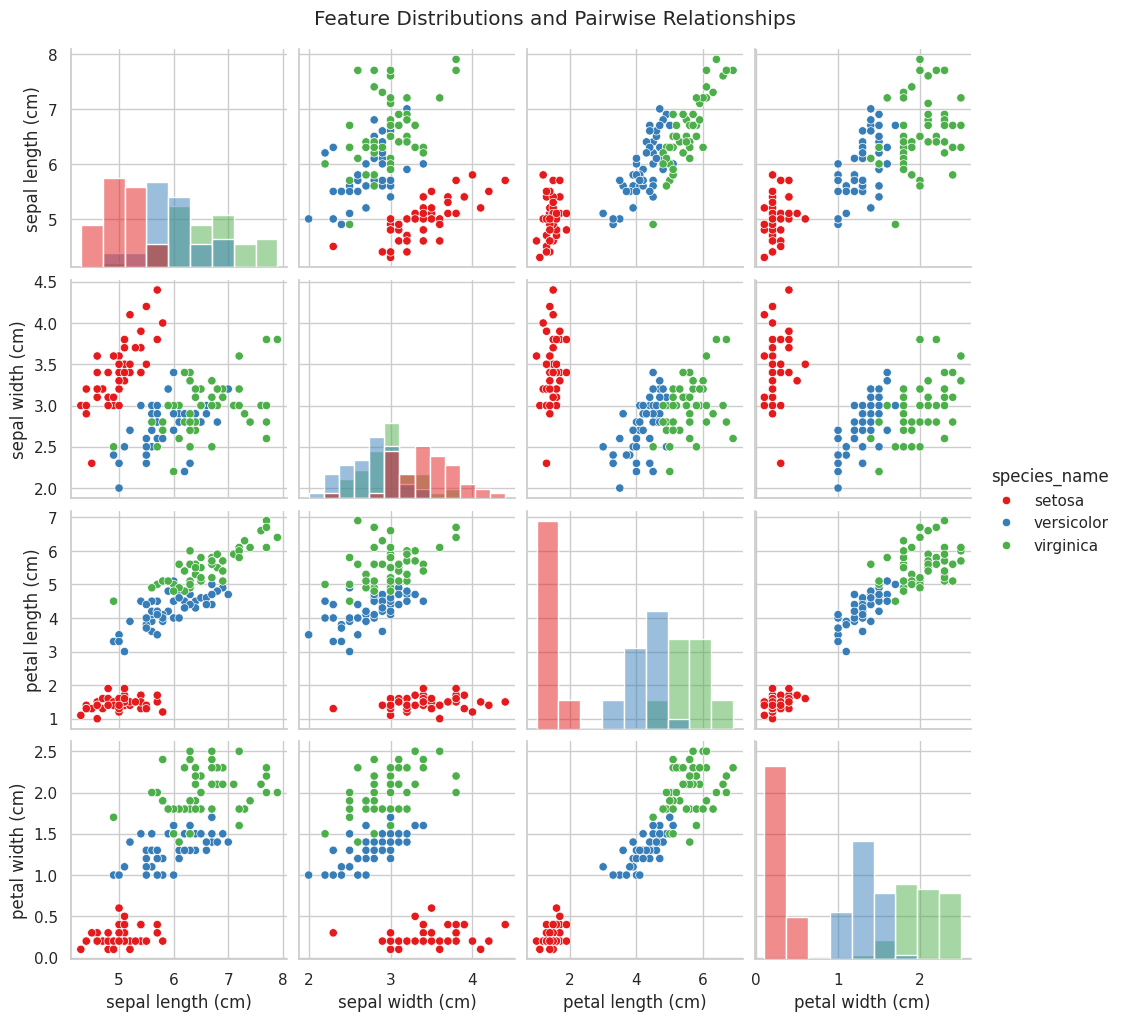

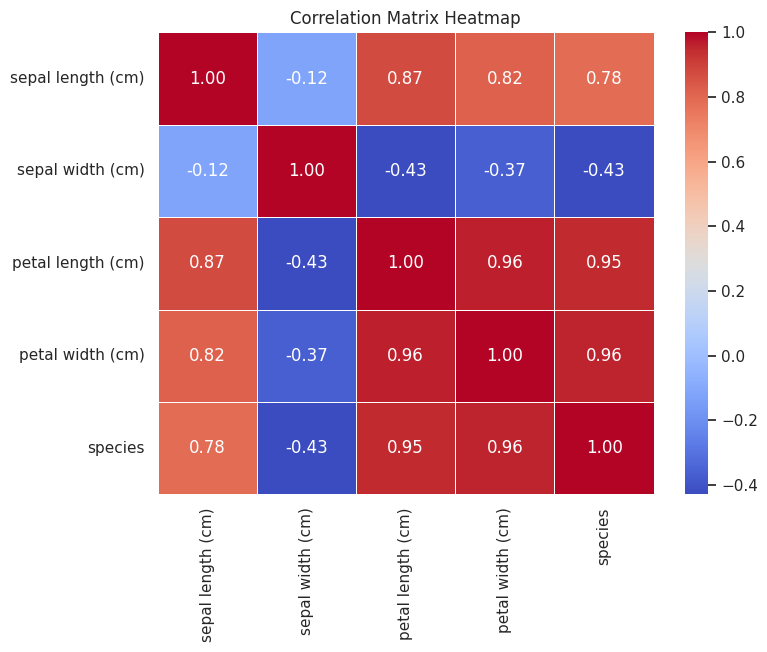

In [ ]:
# Task 2: Exploratory Data Analysis (EDA)

# 1. Dataset structure and summary
print("--- Dataset Information ---")
print(df.info())

print("\n--- Dataset Shape (Rows, Columns) ---")
print(df.shape)

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Statistical Summary ---")
display(df.describe())

# 2. Plot distributions of features (Pairplot)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 8))
pairplot = sns.pairplot(df.drop(columns=['species']), hue='species_name', palette='Set1', diag_kind='hist')
pairplot.fig.suptitle("Feature Distributions and Pairwise Relationships", y=1.02)
plt.show()

# 3. Visualize Correlations Heatmap
plt.figure(figsize=(8, 6))
correlation_matrix = df.drop(columns=['species_name']).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
# Task 3: Data Preprocessing
from sklearn.model_selection import train_test_split

# Define Features (X) and Target (y)
X = df[iris.feature_names]
y = df['species']

# Split dataset: 70% Training, 30% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Total samples: {len(df)}")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Total samples: 150
Training set size: 105 samples
Testing set size: 45 samples


Decision Tree Classifier trained successfully!


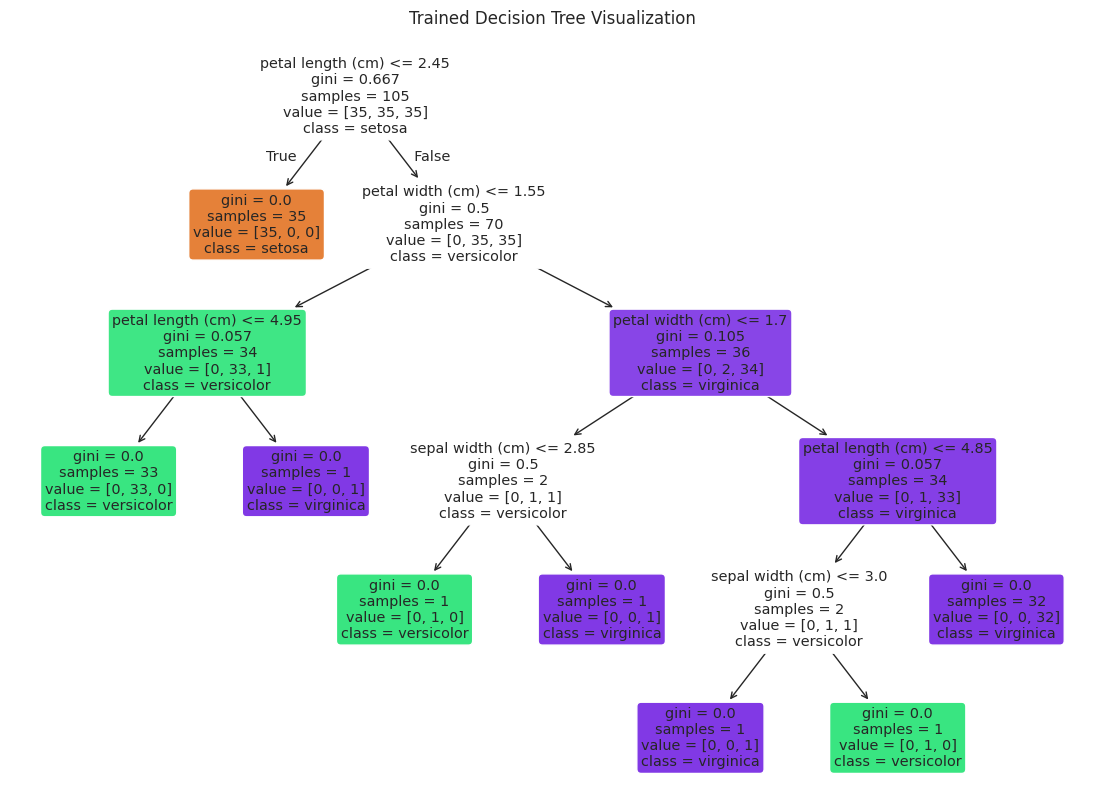

In [ ]:
# Task 4: Build Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Instantiate the Decision Tree model
default_tree = DecisionTreeClassifier(criterion='gini', random_state=42)

# Train (fit) the model
default_tree.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully!")

# Visualize the trained Decision Tree
plt.figure(figsize=(14, 10))
plot_tree(
    default_tree,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.title("Trained Decision Tree Visualization")
plt.show()

--- Model Accuracy ---
Accuracy Score: 93.33%

--- Confusion Matrix ---
[[15  0  0]
 [ 0 12  3]
 [ 0  0 15]]


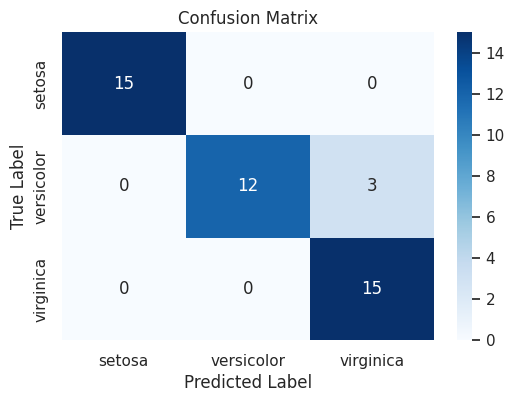


--- Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



In [ ]:
# Task 5: Model Evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict on test data
y_pred = default_tree.predict(X_test)

# Calculate accuracy
acc = accuracy_score(y_test, y_pred)
print(f"--- Model Accuracy ---")
print(f"Accuracy Score: {acc * 100:.2f}%\n")

# Confusion Matrix
print("--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Visual Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

In [ ]:
# Task 6: Experimentation

# 1. Compare 'gini' vs 'entropy'
model_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
model_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)

model_gini.fit(X_train, y_train)
model_entropy.fit(X_train, y_train)

acc_gini = accuracy_score(y_test, model_gini.predict(X_test))
acc_entropy = accuracy_score(y_test, model_entropy.predict(X_test))

print("=== Criterion Comparison ===")
print(f"Gini Criterion Accuracy:    {acc_gini * 100:.2f}%")
print(f"Entropy Criterion Accuracy: {acc_entropy * 100:.2f}%\n")

# 2. Observe Overfitting vs Underfitting by changing hyperparameters
experiments = [
    {"max_depth": 1, "min_samples_split": 2, "desc": "Underfitted (Too shallow)"},
    {"max_depth": 3, "min_samples_split": 2, "desc": "Balanced (Optimal depth)"},
    {"max_depth": 10, "min_samples_split": 2, "desc": "Fully Grown (Risk of Overfitting)"},
    {"max_depth": None, "min_samples_split": 20, "desc": "Pre-pruned with min_samples_split"}
]

print("=== Hyperparameter Experimentation Results ===")
print(f"{'Description':<35} | {'Train Acc':<10} | {'Test Acc':<10}")
print("-" * 62)

for exp in experiments:
    clf = DecisionTreeClassifier(
        criterion='gini',
        max_depth=exp["max_depth"],
        min_samples_split=exp["min_samples_split"],
        random_state=42
    )
    clf.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))

    print(f"{exp['desc']:<35} | {train_acc*100:6.2f}%    | {test_acc*100:6.2f}%")

=== Criterion Comparison ===
Gini Criterion Accuracy:    93.33%
Entropy Criterion Accuracy: 88.89%

=== Hyperparameter Experimentation Results ===
Description                         | Train Acc  | Test Acc  
--------------------------------------------------------------
Underfitted (Too shallow)           |  66.67%    |  66.67%
Balanced (Optimal depth)            |  98.10%    |  97.78%
Fully Grown (Risk of Overfitting)   | 100.00%    |  93.33%
Pre-pruned with min_samples_split   |  98.10%    |  93.33%
